In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns

In [3]:
# Load climate
climate = pd.read_parquet(r"data\temp_precip_daily.parquet")
climate_monthly = pd.read_parquet(r"data\temp_precip_monthly.parquet")

In [5]:
recent_climate = climate[
    climate['date'] >= '1990-01-01'
].copy()

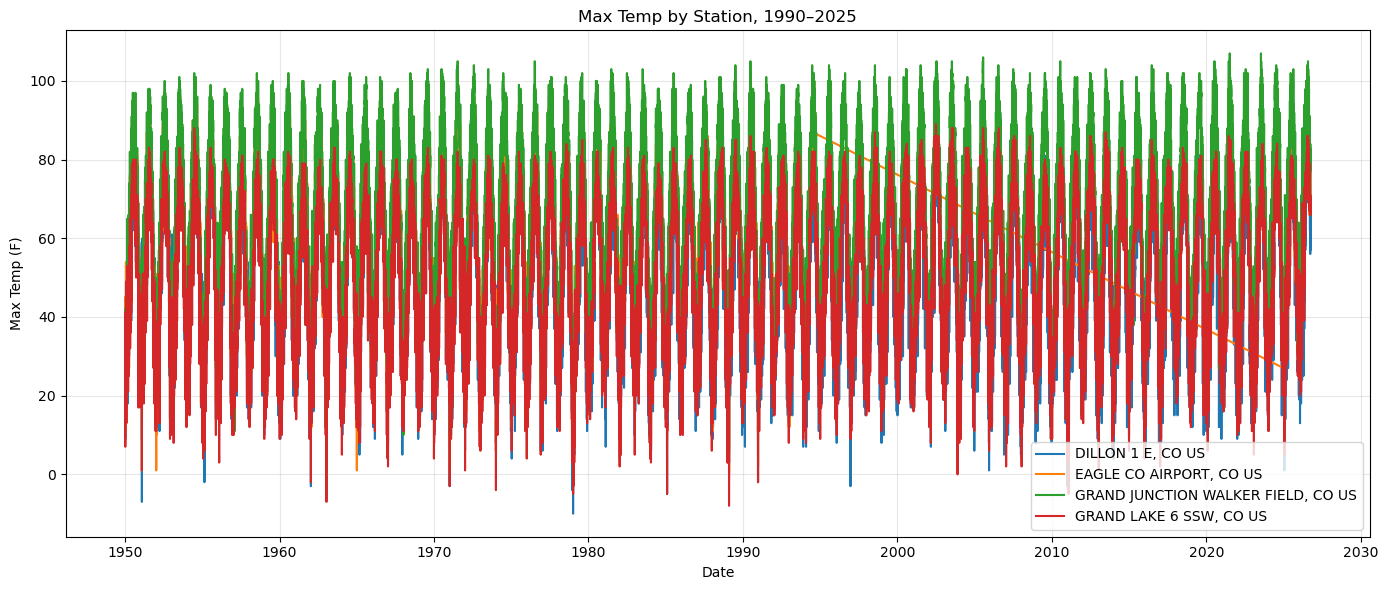

In [6]:
plt.figure(figsize=(14, 6))
for station, group in climate.groupby('name'):
    plt.plot(
        group['date'],
        group['temp_max'],
        label=station
    )

plt.xlabel('Date')
plt.ylabel('Max Temp (F)')
plt.title('Max Temp by Station, 1990–2025')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

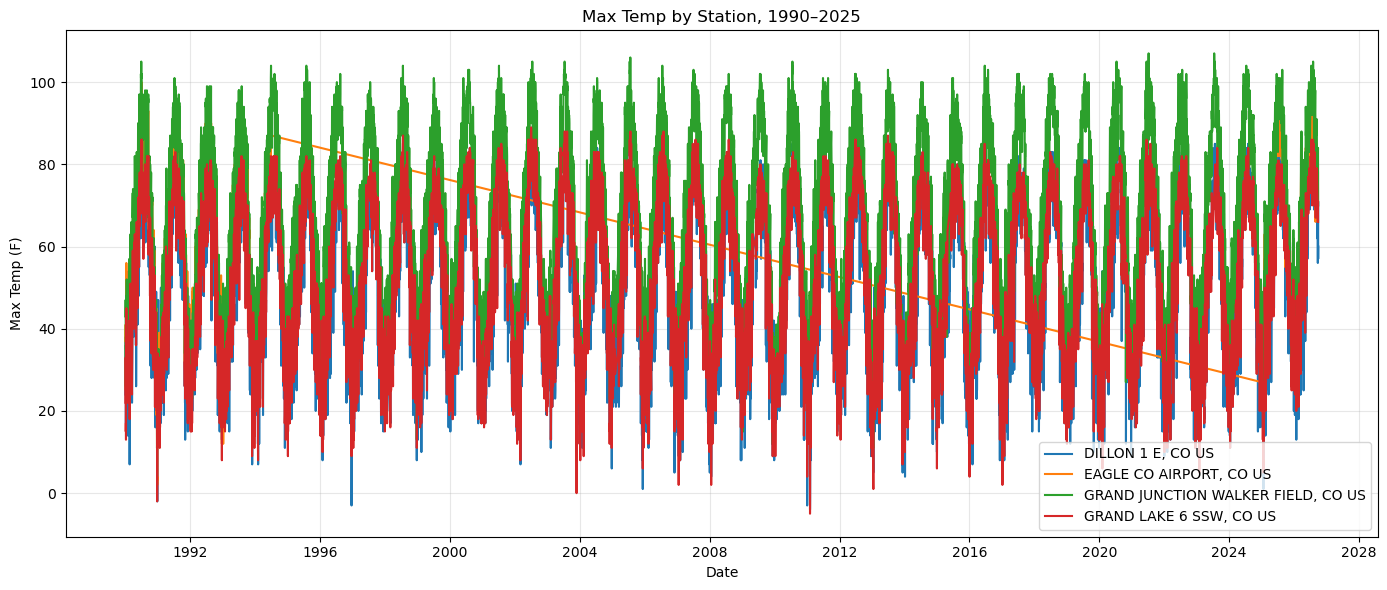

In [8]:
plt.figure(figsize=(14, 6))
for station, group in recent_climate.groupby('name'):
    plt.plot(
        group['date'],
        group['temp_max'],
        label=station
    )

plt.xlabel('Date')
plt.ylabel('Max Temp (F)')
plt.title('Max Temp by Station, 1990–2025')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
climate.groupby('station')['date'].max()

station
USC00052281   2026-09-30
USC00053500   2026-09-28
USW00023063   2026-09-27
USW00023066   2026-09-29
Name: date, dtype: datetime64[ns]

In [12]:
climate.groupby('station')['date'].min()

station
USC00052281   1950-01-01
USC00053500   1950-01-01
USW00023063   1950-01-01
USW00023066   1950-01-01
Name: date, dtype: datetime64[ns]

In [15]:
eagle = recent_climate[
    recent_climate['name'] == 'EAGLE CO AIRPORT, CO US'
].copy()

print(eagle[['date', 'temp_max']].head(20))
print(eagle[['date', 'temp_max']].tail(20))

print("Rows:", len(eagle))
print("Valid Tmax:", eagle['temp_max'].notna().sum())

            date  temp_max
14580 1990-01-01      37.0
14581 1990-01-02      41.0
14582 1990-01-03      27.0
14583 1990-01-04      25.0
14584 1990-01-05      32.0
14585 1990-01-06      31.0
14586 1990-01-07      29.0
14587 1990-01-08      44.0
14588 1990-01-09      53.0
14589 1990-01-10      56.0
14590 1990-01-11      55.0
14591 1990-01-12      50.0
14592 1990-01-13      45.0
14593 1990-01-14      48.0
14594 1990-01-15      42.0
14595 1990-01-16      36.0
14596 1990-01-17      38.0
14597 1990-01-18      28.0
14598 1990-01-19      34.0
14599 1990-01-20      37.0
            date  temp_max
16816 2026-09-08      85.0
16817 2026-09-09      83.0
16818 2026-09-10      84.0
16819 2026-09-11      81.0
16820 2026-09-12      84.0
16821 2026-09-13      83.0
16822 2026-09-14      77.0
16823 2026-09-15      72.0
16824 2026-09-16      70.0
16825 2026-09-17      68.0
16826 2026-09-18      73.0
16827 2026-09-19      68.0
16828 2026-09-20      69.0
16829 2026-09-21      74.0
16830 2026-09-22      77.0
1

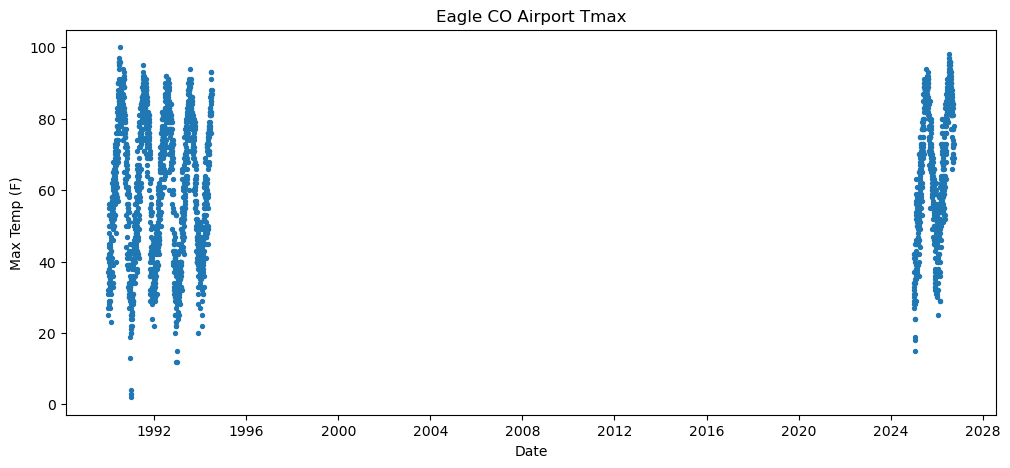

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.scatter(
    eagle['date'],
    eagle['temp_max'],
    s=8
)

plt.title('Eagle CO Airport Tmax')
plt.xlabel('Date')
plt.ylabel('Max Temp (F)')
plt.show()

In [17]:
annual_counts = (
    recent_climate
    .assign(year=recent_climate['date'].dt.year)
    .groupby(['name', 'year'])['temp_max']
    .count()
    .unstack(0)
)

annual_counts

name,"DILLON 1 E, CO US","EAGLE CO AIRPORT, CO US","GRAND JUNCTION WALKER FIELD, CO US","GRAND LAKE 6 SSW, CO US"
year,,,,
1990,365.0,365.0,365.0,365.0
1991,365.0,365.0,365.0,365.0
1992,366.0,366.0,366.0,366.0
1993,365.0,352.0,365.0,365.0
1994,365.0,181.0,365.0,365.0
1995,365.0,NaN,365.0,365.0
1996,366.0,NaN,366.0,362.0
1997,365.0,NaN,365.0,365.0
1998,337.0,NaN,365.0,365.0


In [18]:
noaa_clean = recent_climate[
    recent_climate['name'] != 'EAGLE CO AIRPORT, CO US'
].copy()

In [19]:
monthly_counts = (
    noaa_clean
    .set_index('date')
    .groupby('name')['temp_max']
    .resample('MS')
    .count()
    .reset_index(name='n_days')
)

monthly_counts.head()

,name,date,n_days
0,"DILLON 1 E, CO US",1990-01-01,31
1,"DILLON 1 E, CO US",1990-02-01,28
2,"DILLON 1 E, CO US",1990-03-01,31
3,"DILLON 1 E, CO US",1990-04-01,30
4,"DILLON 1 E, CO US",1990-05-01,31


In [20]:
bad_months = monthly_counts[
    monthly_counts['n_days'] < 20
]

bad_months

,name,date,n_days
97,"DILLON 1 E, CO US",1998-02-01,0
232,"DILLON 1 E, CO US",2009-05-01,0
1063,"GRAND LAKE 6 SSW, CO US",2005-02-01,0
1114,"GRAND LAKE 6 SSW, CO US",2009-05-01,0
1186,"GRAND LAKE 6 SSW, CO US",2015-05-01,0
1210,"GRAND LAKE 6 SSW, CO US",2017-05-01,18
1284,"GRAND LAKE 6 SSW, CO US",2023-07-01,2
1300,"GRAND LAKE 6 SSW, CO US",2024-11-01,15
1322,"GRAND LAKE 6 SSW, CO US",2026-09-01,10


In [21]:


noaa_clean = noaa_clean.sort_values(
    ['name', 'date']
)

In [23]:
basin_daily = (
    noaa_clean
    .groupby('date')
    .agg(
        basin_tmax=('temp_max', 'mean'),
        basin_tmin=('temp_min', 'mean'),
        basin_precip=('precipitation', 'mean'),
        n_temp_stations=('temp_max', 'count'),
        n_precip_stations=('precipitation', 'count')
    )
    .reset_index()
)

In [24]:
noaa_clean.to_parquet(
    r"data\noaa_clean_daily.parquet",
    index=False
)